In [16]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
# =============================================================================
# Standard libraries
# =============================================================================
import os
import sys
import re
import gzip
import shutil
import pickle
from statistics import mode

# =============================================================================
# Third-party libraries
# =============================================================================
import yaml
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import mmread
from scipy.sparse import csr_matrix
from sklearn import preprocessing, metrics
from sklearn.metrics.pairwise import euclidean_distances
from numpy.random import RandomState
import scanpy as sc
import torch
import torch_geometric
from torch_geometric.data import InMemoryDataset, Data, DataLoader
from torch_geometric.utils import *
from tqdm import tqdm
import warnings
# Insert project_dir into sys.path so local modules can be imported
sys.path.insert(0, 'E:\\VSCODE\\PrePR-CT\\Cell-Type-Specific-Graphs-main')
import utils
import model
from utils import *
from model import *
import torch

if torch.cuda.is_available():
    print("CUDA is available. GPU:", torch.cuda.get_device_name(0))
else:
    print("CUDA is not available.")

# =============================================================================
# Warning configuration
# =============================================================================
warnings.simplefilter(action='ignore', category=RuntimeWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

# =============================================================================
# Configuration loader
# =============================================================================
'''def load_config(config_file):
    """Load configuration parameters from a YAML file."""
    with open(config_file, 'r') as f:
        config = yaml.safe_load(f)
    return config
    '''

def load_config(config_file):
    """Load configuration parameters from a YAML file."""
    with open(config_file, 'r', encoding='utf-8-sig') as f:
        config = yaml.safe_load(f)
    return config

CUDA is available. GPU: NVIDIA GeForce RTX 4060 Laptop GPU


In [17]:
# Specify the configuration file path
config_file = "E:\\VSCODE\\PrePR-CT\\Cell-Type-Specific-Graphs-main\\training\\config_train_Kang.yaml"

# Load configuration parameters from the YAML file
config = load_config(config_file)

# Extract configuration values (with defaults)
project_dir       = config.get('project_dir', '/../Cell-Type-Specific-Graphs/')
data_path         = config.get('data_path', 'Data/')
dataset           = config.get('dataset_h5ad', 'Neurips_Data_Processed.h5ad')
save_path_results = config.get('save_path_results', 'Results/')
save_path_models  = config.get('save_path_models', 'model_checkpoints/')
graphs_path       = config.get('graphs_path', 'graphs/')
graphs_data       = config.get('graphs_data', 'NeurIPS')
SMILES_feat       = config.get('SMILES_feat', 'SMILES_feat.csv')
multi_pert        = config.get('multi_pert', True)

# New parameters: testing cell type and testing drugs
testing_cell_type = config.get('testing_cell_type', ['B cells'])
testing_drugs     = config.get('testing_drugs', ["RG7090", "HYDROXYUREA"])

# Build full paths
full_data_path         = os.path.join(project_dir, data_path)
full_dataset_path      = os.path.join(full_data_path, dataset)
full_save_path_results = os.path.join(project_dir, save_path_results)
full_save_path_models  = os.path.join(project_dir, save_path_models)
full_graphs_path       = os.path.join(project_dir, graphs_path, graphs_data)
SMILES_feat_path       = os.path.join(full_data_path, SMILES_feat)

if len(testing_cell_type) > 1:
  full_save_path_results = full_save_path_results + '_unseen_pert_'


# Extract training parameters from the YAML file
params = config.get('params', {
    'hidden_channels': 128,
    'weight_decay': 1e-05,
    'in_head': 1,
    'learning_rate': -3,
    'num_epochs': 100,
    'batch_size': 256
})

# Print configuration for verification
print("Project Directory:", project_dir)
print("Data Path:", full_data_path)
print("Dataset Path:", full_dataset_path)
print("Graphs Path:", full_graphs_path)
print("Results Save Path:", full_save_path_results)
print("Models Save Path:", full_save_path_models)
print("Training Parameters:", params)
print("Testing Cell Type:", testing_cell_type)
print("Testing Drugs:", testing_drugs)

# =============================================================================
# Import Data
# =============================================================================
adata = sc.read(full_dataset_path)
del adata.raw


# -----------------------------------------------------------------------------
# Check and add required columns in adata.obs if not present
# -----------------------------------------------------------------------------



adata.obs['cov_drug'] = (adata.obs['cell_type'].astype(str) + '_' + adata.obs['condition'].astype(str))
# -----------------------------------------------------------------------------
# Load the coexpression network for each unique cell type
# -----------------------------------------------------------------------------
cell_type_network = {}
for cell_type in adata.obs.cell_type.unique():
    print(f"Loading network for: {cell_type}")
    graph_path = os.path.join(full_graphs_path, f"{cell_type}_coexpr_graph.pkl")
    cell_type_network[cell_type] = torch.load(graph_path)

# -----------------------------------------------------------------------------
# Matching Control & Treatment
# -----------------------------------------------------------------------------

ctrl_data = adata[adata.obs.condition == 'control']

# For each unique cell type, compute the mean and variance from control data
# and store them in the corresponding network object.
for cell_type in adata.obs.cell_type.unique():
    genes = cell_type_network[cell_type].pos.tolist()
    ctrl_subset = ctrl_data[ctrl_data.obs.cell_type == cell_type, genes].copy()
    
    # Compute mean and variance along the cell dimension (axis 0)
    mean_expr = torch.mean(torch.tensor(ctrl_subset.X.A), dim=0)
    var_expr  = torch.var(torch.tensor(ctrl_subset.X.A), dim=0)
    
    # Concatenate mean and variance (as separate columns) and assign to the network
    cell_type_network[cell_type].x = torch.cat(
        [mean_expr.unsqueeze(1), var_expr.unsqueeze(1)],
        dim=1
    )

Project Directory: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main
Data Path: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main\Data/
Dataset Path: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main\Data/Kang.h5ad
Graphs Path: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main\graphs/Kang
Results Save Path: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main\Results/
Models Save Path: E:/VSCODE/PrePR-CT/Cell-Type-Specific-Graphs-main\model_checkpoints/
Training Parameters: {'hidden_channels': 64, 'weight_decay': 1e-05, 'in_head': 1, 'learning_rate': -3, 'num_epochs': 100, 'batch_size': 256}
Testing Cell Type: ['CD4 T cells']
Testing Drugs: ['stimulated']
Loading network for: CD14+ Monocytes
Loading network for: CD4 T cells
Loading network for: Dendritic cells
Loading network for: NK cells
Loading network for: CD8 T cells
Loading network for: B cells
Loading network for: FCGR3A+ Monocytes


Cells (train, OOD): 6774 5087
模型： torch.float32
训练数据 x： torch.float32
训练数据 y： torch.float32
Training Starts


  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

Epoch 0, train loss: 12.059458767926252


  0%|          | 0/27 [00:00<?, ?it/s]

...

-------------------------------------------- Mean Expression Prediction -----------------------------------------------------------
模型和 OOD 数据的 dtype 已统一为 float32


  0%|          | 0/20 [00:00<?, ?it/s]

CD4 T cells_stimulated  mse:  0.007246164
R² value for predicting the **mean** expression of all genes for perturbation 'CD4 T cells_stimulated': 0.9793
R² value for predicting the **mean** of the top 100 DEGs for perturbation 'CD4 T cells_stimulated': 0.9939
-------------------------------------------- Std Expression Prediction -----------------------------------------------------------


  0%|          | 0/20 [00:00<?, ?it/s]

CD4 T cells_stimulated  mse:  0.007246168
R² value for predicting the **standard deviation** expression of all genes for perturbation 'CD4 T cells_stimulated': 0.8261
R² value for predicting the **standard deviation** of the top 100 DEGs for perturbation 'CD4 T cells_stimulated': 0.9165


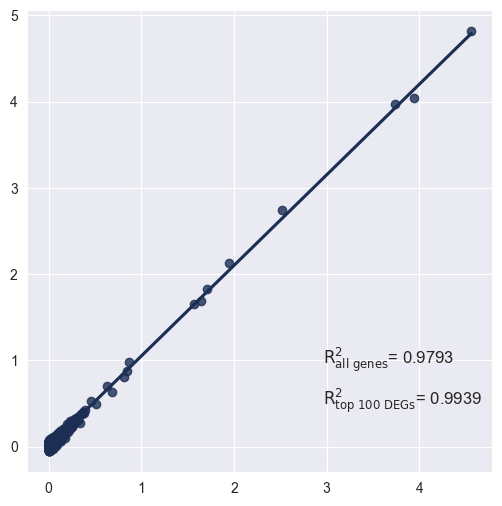

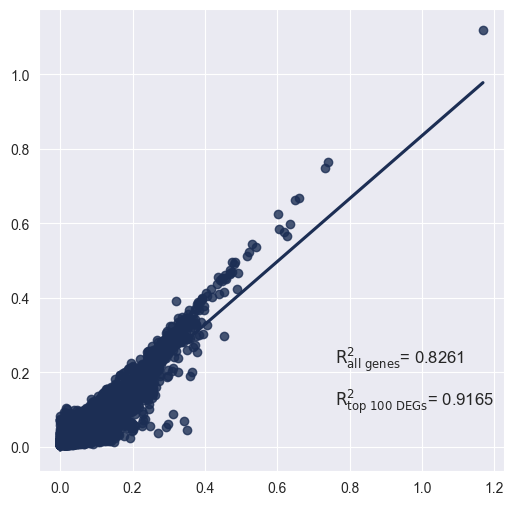

In [31]:
# -----------------------------------------------------------------------------
# Prepare Data for Training
# -----------------------------------------------------------------------------

# Load preprocessed cell data (graphs) from pickle file
with open(full_data_path + 'cells_'+graphs_data+'.pkl', 'rb') as pickle_file:
    cell_all_Data = pickle.load(pickle_file)
    
# Extract unique cov_drug identifiers for the chosen testing drugs and testing cell types
testing_cov_drug = list(adata[
    ((adata.obs['condition'].isin(testing_drugs)) & 
    (adata.obs['cell_type'].isin(testing_cell_type)))
].copy().obs['cov_drug'].unique())

# Partition data into training cells and OOD (out-of-distribution) cells
cells_ood = [sample for sample in cell_all_Data if sample.cov_drug in testing_cov_drug]
cells_train = [sample for sample in cell_all_Data if sample.cov_drug not in testing_cov_drug]

# Print dataset size for each split
print("Cells (train, OOD):", len(cells_train), len(cells_ood))

# -----------------------------------------------------------------------------
# Training & Testing
# -----------------------------------------------------------------------------

# Create a DataLoader for training data
train_dataloader = DataLoader(cells_train, batch_size=params['batch_size'], shuffle=True)

# Fix random seed for reproducibility
torch.manual_seed(42) 

# Initialize GNN model with given parameters
model = GNN(total_genes  = len(adata.var), num_perts = 110, act_fct = 'Sigmoid',
            hidden_channels = params['hidden_channels'], in_head = params['in_head'],  
            multi_pert = multi_pert).to(device)

###
import torch

# 1. 模型统一为 float32
model = model.float()

# 2. 训练数据统一为 float32
for data in train_dataloader.dataset:
    if hasattr(data, "x") and data.x is not None:
        data.x = data.x.float()
    if hasattr(data, "y") and data.y is not None:
        data.y = data.y.float()

# 3. 细胞类型图的节点特征也统一为 float32
for cell in cell_type_network:
    graph = cell_type_network[cell]
    if hasattr(graph, "x") and graph.x is not None:
        graph.x = graph.x.float()

print("模型：", next(model.parameters()).dtype)
print("训练数据 x：", train_dataloader.dataset[0].x.dtype)
print("训练数据 y：", train_dataloader.dataset[0].y.dtype)
###
# Train the model using training set
model = train(model = model, num_epochs = params['num_epochs'], 
              lr = 10**params['learning_rate'],
              weight_decay = params['weight_decay'], multi_pert = multi_pert, 
              cell_type_network = cell_type_network, train_loader = train_dataloader)

# Save trained model weights to disk
torch.save(model.state_dict(), full_save_path_models+'_'+graphs_data+"_model.pt")

# Reload the saved model weights (to verify persistence and consistency)
model.load_state_dict(torch.load(full_save_path_models+'_'+graphs_data+"_model.pt"))

# Dictionary to store DEGs (Differentially Expressed Genes) for each cov_drug
degs_dict = {}

# Iterate through each cov_drug in the testing set to compute DEGs
for cov_drug in tq.tqdm(set(adata[adata.obs.cov_drug.isin(testing_cov_drug)].obs.cov_drug.unique())):
    testing_drug = cov_drug.split('_')[1]          # Extract drug name
    ood_cell = cov_drug.split('_')[0]              # Extract cell type
    genes = cell_type_network[ood_cell].pos.tolist()  # Genes for this cell type graph

    # Subset adata for cov_drug and its control
    adata_cov = adata[
        adata.obs.cov_drug.isin([cov_drug, ood_cell + '_control']), genes
    ].copy()

    # Perform DEG analysis using t-test with BH correction
    sc.tl.rank_genes_groups(
        adata_cov,
        groupby='cov_drug',
        rankby_abs=True,
        method='t-test',
        corr_method='benjamini-hochberg',
        reference=ood_cell + '_control',
        n_genes=len(adata_cov.var)
    )

    # Extract DEGs as DataFrame
    dedf = sc.get.rank_genes_groups_df(adata_cov, group=cov_drug)

    # Filter significant DEGs (adjusted p-value < 0.05)
    dedf = dedf.loc[dedf['pvals_adj'] < 0.05].copy()

    # Get ranked gene names
    DEGs_name = rank_genes(dedf)

    # Create boolean mask for selected DEGs
    mask = adata_cov.var_names.isin(DEGs_name)

    # Convert mask to indices
    indices_np = np.where(mask)[0]

    # Store DEG indices for this cov_drug
    degs_dict[cov_drug] = indices_np

# Create DataLoader for OOD evaluation data
ood_loader_all = DataLoader(cells_ood, batch_size=params['batch_size'], shuffle=True)

# Run inference for mean expression prediction
print("-------------------------------------------- Mean Expression Prediction -----------------------------------------------------------")
###
import torch

# 1. 模型统一为 float32
model = model.float()

# 2. OOD 推理数据统一为 float32
for data in ood_loader_all.dataset:
    if getattr(data, "x", None) is not None:
        data.x = data.x.float()
    if getattr(data, "y", None) is not None:
        data.y = data.y.float()

# 3. 细胞类型图的节点特征统一为 float32
for cell in cell_type_network:
    graph = cell_type_network[cell]
    if getattr(graph, "x", None) is not None:
        graph.x = graph.x.float()

print("模型和 OOD 数据的 dtype 已统一为 float32")

###
Inference_multi_pert(cell_type_network, model, full_save_path_results, 
                    ood_loader_all, adata, degs_dict = degs_dict, mean_or_std = True, 
                    plot = True, multi_pert = multi_pert) 
                    
# Run inference for standard deviation expression prediction
print("-------------------------------------------- Std Expression Prediction -----------------------------------------------------------")
Inference_multi_pert(cell_type_network, model, full_save_path_results, 
                    ood_loader_all, adata, degs_dict = degs_dict, mean_or_std = False, 
                    plot = True, multi_pert = multi_pert)

In [9]:
import torch

print("===== 模型参数 dtype =====")
for name, param in model.named_parameters():
    print(name, param.dtype)
    break

print("\n===== 训练数据 dtype =====")
for batch in train_dataloader:
    print("batch 类型:", type(batch))

    if hasattr(batch, "to_dict"):
        batch = batch.to_dict()

    if isinstance(batch, dict):
        for key, value in batch.items():
            if torch.is_tensor(value):
                print(key, value.dtype, tuple(value.shape))
            elif isinstance(value, (list, tuple)):
                for i, item in enumerate(value[:3]):
                    if torch.is_tensor(item):
                        print(f"{key}[{i}]", item.dtype, tuple(item.shape))
    break

===== 模型参数 dtype =====
conv1.lin_key.weight torch.float32

===== 训练数据 dtype =====
batch 类型: <class 'torch_geometric.data.batch.DataBatch'>
x torch.float64 (256, 5000)
y torch.float64 (256, 5000)
batch torch.int64 (256,)
ptr torch.int64 (257,)


In [11]:
# ===== 修复 PrePR-CT 训练数据的 dtype =====
import torch

def fix_dataloader_dtype(dataloader):
    """将 PyTorch Geometric 数据中的浮点特征统一为 float32。"""
    for data in dataloader.dataset:
        if hasattr(data, "x") and data.x is not None:
            data.x = data.x.float()

        if hasattr(data, "y") and data.y is not None:
            data.y = data.y.float()

    return dataloader


train_dataloader = fix_dataloader_dtype(train_dataloader)

# 检查修复结果
batch = next(iter(train_dataloader))
print("x dtype:", batch.x.dtype)
print("y dtype:", batch.y.dtype)
print("模型 dtype:", next(model.parameters()).dtype)

x dtype: torch.float32
y dtype: torch.float32
模型 dtype: torch.float32


In [22]:
# ===== 定位 PrePR-CT 中 dtype 不匹配的具体线性层 =====
import torch

dtype_debug_hooks = []

def debug_linear_dtype(module, inputs):
    weight = getattr(module, "weight", None)

    if weight is None:
        return

    for x in inputs:
        if torch.is_tensor(x) and x.is_floating_point():
            if x.dtype != weight.dtype:
                print("\n发现 dtype 不一致！")
                print("层名称：", module)
                print("输入 dtype：", x.dtype)
                print("输入 shape：", tuple(x.shape))
                print("权重 dtype：", weight.dtype)
                print("权重 shape：", tuple(weight.shape))

                raise RuntimeError(
                    "已定位 dtype 不匹配的线性层；"
                    "请根据上面的信息修复源头。"
                )

# 移除之前注册的钩子，避免旧钩子干扰诊断
for hook in dtype_hooks:
    hook.remove()
dtype_hooks.clear()

# 在每个 Linear 层执行前检查输入
for name, layer in model.named_modules():
    if isinstance(layer, torch.nn.Linear):
        hook = layer.register_forward_pre_hook(debug_linear_dtype)
        dtype_debug_hooks.append(hook)

print("已为", len(dtype_debug_hooks), "个 Linear 层启用 dtype 诊断。")

已为 3 个 Linear 层启用 dtype 诊断。


In [19]:
import torch
import torch.nn.functional as F
import traceback

# 保存原始函数
_original_linear = F.linear

def debug_linear(input, weight, bias=None):
    if input.dtype != weight.dtype:
        print("\n===== 定位到真正的 dtype 冲突 =====")
        print("input dtype:", input.dtype)
        print("input shape:", tuple(input.shape))
        print("weight dtype:", weight.dtype)
        print("weight shape:", tuple(weight.shape))
        print("bias dtype:", bias.dtype if bias is not None else None)
        traceback.print_stack(limit=8)
        raise RuntimeError(
            f"F.linear dtype mismatch: input={input.dtype}, "
            f"weight={weight.dtype}"
        )

    return _original_linear(input, weight, bias)

# 安装诊断包装
F.linear = debug_linear

print("诊断已开启。现在重新运行原来的训练单元格。")

诊断已开启。现在重新运行原来的训练单元格。


In [21]:
import torch
import torch.nn.functional as F

F.linear = _original_linear

In [28]:
import inspect
import torch

for name, module in model.named_modules():
    if isinstance(module, torch.nn.Linear):
        try:
            print(f"层名称: {name}")
            print(f"定义文件: {inspect.getfile(type(module))}")
            print(f"权重类型: {module.weight.dtype}")
            print("-" * 40)
        except (TypeError, OSError):
            pass

层名称: embd_pert.network.0
定义文件: e:\Anaconda\envs\preprct\lib\site-packages\torch\nn\modules\linear.py
权重类型: torch.float32
----------------------------------------
层名称: lin_predict.network.0
定义文件: e:\Anaconda\envs\preprct\lib\site-packages\torch\nn\modules\linear.py
权重类型: torch.float32
----------------------------------------
层名称: lin_predict.network.2
定义文件: e:\Anaconda\envs\preprct\lib\site-packages\torch\nn\modules\linear.py
权重类型: torch.float32
----------------------------------------
